# Fit a support-vector machine with NumPy

The main Lecture 9 notebook uses `sklearn.svm.SVC` to study margins,
nonlinear boundaries, multiclass strategies, and a real-data pipeline. Here
we build the **binary fitting and prediction core** ourselves: margins and
hinge loss, the linear primal objective, an RBF Gram matrix, and the kernel
dual optimization. We then fit `SVC` on the **same rows** and compare scores,
predictions, support vectors, and objectives. This small implementation is
for learning; it does not reproduce every production solver feature.

Run cells in order. NumPy performs every fit below; scikit-learn appears only
in the last comparison cells. Labels are $y_i\in\{-1,+1\}$.

training matrix: (50, 2) test matrix: (20, 2)


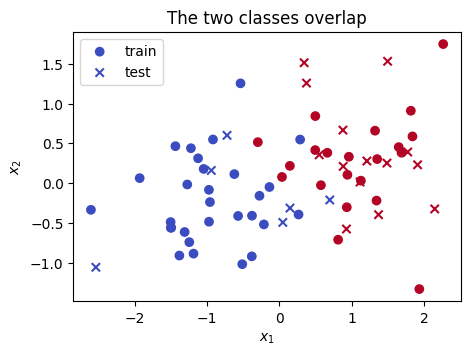

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(26509)

# An overlapping linear example, with an independent test set.
X_linear = np.r_[rng.normal((-1.0, -.2), .65, (35, 2)),
                 rng.normal((1.0, .2), .65, (35, 2))]
y_linear = np.r_[-np.ones(35), np.ones(35)]
order = rng.permutation(len(y_linear))
train, test = order[:50], order[50:]
Xtr, ytr = X_linear[train], y_linear[train]
Xte, yte = X_linear[test], y_linear[test]
print('training matrix:', Xtr.shape, 'test matrix:', Xte.shape)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, cmap='coolwarm', label='train')
ax.scatter(Xte[:, 0], Xte[:, 1], c=yte, cmap='coolwarm', marker='x', label='test')
ax.set(xlabel='$x_1$', ylabel='$x_2$', title='The two classes overlap')
ax.legend(); plt.show()

## 1. Margins and the linear objective

For score $f(x)=w^\top x+b$, the signed functional margin is
$m_i=y_i f(x_i)$. The hinge loss is $\max(0,1-m_i)$: zero beyond margin one,
positive for a point inside that margin, and greater than one for a
misclassified point. The objective in scikit-learn's $C$ convention is

$$J(w,b)=\tfrac12\|w\|_2^2+C\sum_{i=1}^n\max\{0,1-y_i(w^\top x_i+b)\}.$$

The intercept is not penalized. We will optimize the equivalent objective
$J/(nC)$ because its mean hinge loss is convenient to calculate.

In [2]:
def linear_score(X, w, b):
    # X: (n, d); w: (d,); result: (n,).
    return X @ w + b

def mean_hinge(X, y, w, b):
    margins = y * linear_score(X, w, b)
    return np.maximum(0.0, 1.0 - margins).mean()

def primal_objective(X, y, w, b, C):
    return .5 * (w @ w) + C * len(y) * mean_hinge(X, y, w, b)

zero = np.zeros(Xtr.shape[1])
assert np.isclose(mean_hinge(Xtr, ytr, zero, 0.0), 1.0)
assert np.isclose(primal_objective(Xtr, ytr, zero, 0.0, 1.0), len(ytr))
print('At w=b=0, each point has hinge loss 1.')

At w=b=0, each point has hinge loss 1.


## 2. Fit a linear SVM by subgradient descent

The hinge loss has a corner at $m_i=1$, so an ordinary derivative does not
exist there. A **subgradient** is a slope supporting a convex function from
below; at the corner, any slope between the one-sided slopes works. We choose
zero hinge contribution at equality. Let $\lambda=1/(nC)$ and minimize
$J/(nC)$. At iteration $t$:

1. Compute every margin $m_i=y_i(w_t^\top x_i+b_t)$.
2. Mark rows with margin below one as active. Their hinge contributions are
   $-y_i x_i$ for $w$ and $-y_i$ for $b$; inactive rows contribute zero.
   Add the regularizer's $\lambda w_t$ to the first derivative.
3. Move against these subgradients:
   $w_{t+1}=w_t-\eta_t g_w$ and $b_{t+1}=b_t-\eta_t g_b$.

Thus the **full-batch** subgradient, using all $n$ rows at each update, is

$$g_w=\lambda w-\frac1n\sum_{m_i<1}y_i x_i,\qquad
g_b=-\frac1n\sum_{m_i<1}y_i.$$

At $w_0=b_0=0$, every margin is zero, so every row is active. The next cell
calculates the first update without a loop. `X.T @ y` sums the signed
feature vectors and `.mean()` averages the signed labels. This is not
stochastic gradient descent: no row is sampled. A decreasing step size
$\eta_t=\eta_0/\sqrt{t+1}$ helps this nonsmooth method settle, although
individual updates need not lower the objective.

In [3]:
C_linear = 1.0
step0 = .3
n = len(ytr)
first_margin = ytr * linear_score(Xtr, np.zeros(Xtr.shape[1]), 0.0)
first_active = first_margin < 1.0
first_grad_w = -Xtr[first_active].T @ ytr[first_active] / n
first_grad_b = -ytr[first_active].sum() / n
first_w = -step0 * first_grad_w
first_b = -step0 * first_grad_b
print('active rows at start:', first_active.sum(), 'of', n)
print('first subgradient:', np.round(first_grad_w, 4), round(first_grad_b, 4))
print('after one update:', np.round(first_w, 4), round(first_b, 4))
assert first_active.all()

active rows at start: 50 of 50
first subgradient: [-0.9844 -0.2239] 0.16
after one update: [0.2953 0.0672] -0.048


w: [2.0283 0.4125] b: -0.3543
training objective: 9.4048
test accuracy: 0.95


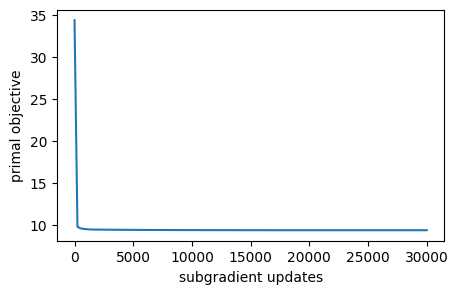

In [4]:
def fit_linear_numpy(X, y, C=1.0, steps=30_000, step0=.3):
    n, d = X.shape
    lam = 1.0 / (n * C)
    w = np.zeros(d)
    b = 0.0
    history = []
    for t in range(steps):
        margin = y * linear_score(X, w, b)
        active = margin < 1.0
        grad_w = lam * w - X[active].T @ y[active] / n
        grad_b = -y[active].sum() / n
        step = step0 / np.sqrt(t + 1.0)
        w -= step * grad_w
        b -= step * grad_b
        if t % 250 == 0 or t == steps - 1:
            history.append((t + 1, primal_objective(X, y, w, b, C)))
    return w, b, np.asarray(history)

w, b, history = fit_linear_numpy(Xtr, ytr, C=C_linear)
one_step_w, one_step_b, _ = fit_linear_numpy(
    Xtr, ytr, C=C_linear, steps=1, step0=step0)
assert np.allclose(one_step_w, first_w) and np.isclose(one_step_b, first_b)
linear_test_score = linear_score(Xte, w, b)
linear_test_prediction = np.where(linear_test_score >= 0, 1.0, -1.0)
print('w:', np.round(w, 4), 'b:', round(b, 4))
print('training objective:', round(history[-1, 1], 4))
print('test accuracy:', np.mean(linear_test_prediction == yte))
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(history[:, 0], history[:, 1])
ax.set(xlabel='subgradient updates', ylabel='primal objective')
plt.show()

## 3. Why kernels lead to a dual problem

The fitted score can be written using training rows:
$f(x)=\sum_i\alpha_i y_i K(x_i,x)+b$. For a linear kernel,
$K(x_i,x)=x_i^\top x$, so $w=\sum_i\alpha_i y_i x_i$. For an RBF kernel,

$$K_\gamma(x,x')=\exp(-\gamma\|x-x'\|_2^2),$$

we can evaluate the score without constructing the feature vector. The Gram
matrix has entries $K_{ij}=K(x_i,x_j)$ and shape $n\times n$. The dual solves

$$\max_{\alpha}\ \mathbf1^\top\alpha-
\tfrac12(\alpha\odot y)^\top K(\alpha\odot y),\quad
0\leq\alpha_i\leq C,\quad y^\top\alpha=0.$$

The last constraint is why a coordinate step changes **two** multipliers.
Rows with $\alpha_i>0$ are support vectors. The following distance identity
avoids a Python loop over pairs of rows:

$$\|a-b\|_2^2=\|a\|_2^2+\|b\|_2^2-2a^\top b.$$

`A @ B.T` computes all cross-inner-products. The two squared-norm arrays
then broadcast over its rows and columns. The `maximum` clips tiny negative
roundoff before exponentiation. This forms the full training Gram matrix;
prediction later needs similarities only to support vectors.

In [5]:
def kernel_matrix(A, B, kind='linear', gamma=1.0):
    # A: (n, d); B: (m, d); result: (n, m).
    if kind == 'linear':
        return A @ B.T
    if kind == 'rbf':
        a2 = np.sum(A*A, axis=1)[:, None]
        b2 = np.sum(B*B, axis=1)[None, :]
        squared_distance = np.maximum(a2 + b2 - 2*A@B.T, 0.0)
        return np.exp(-gamma * squared_distance)
    raise ValueError('kind must be linear or rbf')

K = kernel_matrix(Xtr, Xtr, kind='rbf', gamma=2.0)
print('Gram shape:', K.shape, 'symmetry error:', np.max(np.abs(K-K.T)))
assert np.allclose(K, K.T)
assert np.allclose(np.diag(K), 1.0)

Gram shape: (50, 50) symmetry error: 0.0


## 4. Pairwise dual updates (simplified SMO)

For one multiplier $\alpha_i$, compute its score error
$E_i=f(x_i)-y_i$. The Karush--Kuhn--Tucker (KKT) conditions say:

- $\alpha_i=0$ permits $m_i\geq1$ (a non-support vector);
- $0<\alpha_i<C$ requires $m_i=1$ (on a margin);
- $\alpha_i=C$ permits $m_i\leq1$ (inside a margin or misclassified).

A row violates these conditions if it needs a larger multiplier but is below
its margin, or needs a smaller multiplier but is above it. We choose a second
row $j$ with a large difference in score errors and update the pair while
preserving $y^\top\alpha=0$. Bounds $L,H$ keep both multipliers in $[0,C]$.

The function below uses the standard two-coordinate update. `eta` is the
squared feature-space distance between rows $i$ and $j$; when it is nearly
zero, the pair is skipped. In the code, with old values $a_i,a_j$,

$$\eta=K_{ii}+K_{jj}-2K_{ij},\qquad
a_j^{\rm new}=\operatorname{clip}\!\left(
a_j+\frac{y_j(E_i-E_j)}{\eta},L,H\right),\qquad
a_i^{\rm new}=a_i+y_i y_j(a_j-a_j^{\rm new}).$$

When $y_i\ne y_j$, $L=\max(0,a_j-a_i)$ and
$H=\min(C,C+a_j-a_i)$; when $y_i=y_j$,
$L=\max(0,a_i+a_j-C)$ and $H=\min(C,a_i+a_j)$. These bounds and the last
equation preserve both constraints on $\alpha$. The intercept is updated so
that a newly interior support vector has signed margin one. We count full
passes with no updates as a stopping criterion. The algorithm is:

1. Precompute $K$; initialize $\alpha=0$ and $b=0$.
2. Scan rows $i$ in shuffled order. If a row violates a KKT condition, try
   partners $j$ until a two-coordinate update succeeds.
3. Repeat until enough full passes make no change, or reach the epoch cap.

This educational solver is intended for small,
well-scaled examples; production `SVC` uses a more sophisticated solver.

In [6]:
def fit_kernel_numpy(X, y, C=1.0, kind='rbf', gamma=2.0,
                     tol=1e-4, max_passes=30, max_epochs=3000, seed=26509):
    X = np.asarray(X, float)
    y = np.asarray(y, float)
    if set(np.unique(y)) != {-1.0, 1.0}:
        raise ValueError('binary labels must be -1 and +1')
    K = kernel_matrix(X, X, kind=kind, gamma=gamma)
    n = len(y)
    alpha = np.zeros(n)
    b = 0.0
    random = np.random.default_rng(seed)
    quiet_passes = 0
    epochs = 0
    while quiet_passes < max_passes and epochs < max_epochs:
        changed = 0
        for i in random.permutation(n):
            scores = K @ (alpha*y) + b
            errors = scores - y
            Ei = errors[i]
            if not ((y[i]*Ei < -tol and alpha[i] < C-tol) or
                    (y[i]*Ei > tol and alpha[i] > tol)):
                continue
            # Try the largest error difference first, then other rows.
            candidates = np.argsort(-np.abs(Ei-errors))
            for j in candidates:
                if i == j:
                    continue
                ai, aj = alpha[i], alpha[j]
                if y[i] != y[j]:
                    low, high = max(0.0, aj-ai), min(C, C+aj-ai)
                else:
                    low, high = max(0.0, ai+aj-C), min(C, ai+aj)
                if high-low < 1e-12:
                    continue
                eta = K[i, i] + K[j, j] - 2*K[i, j]
                if eta < 1e-12:
                    continue
                new_aj = np.clip(aj + y[j]*(Ei-errors[j])/eta, low, high)
                if abs(new_aj-aj) < 1e-10:
                    continue
                new_ai = ai + y[i]*y[j]*(aj-new_aj)
                da, dj = new_ai-ai, new_aj-aj
                b1 = b-Ei-y[i]*da*K[i, i]-y[j]*dj*K[i, j]
                b2 = b-errors[j]-y[i]*da*K[i, j]-y[j]*dj*K[j, j]
                if 1e-8 < new_ai < C-1e-8:
                    b = b1
                elif 1e-8 < new_aj < C-1e-8:
                    b = b2
                else:
                    b = .5*(b1+b2)
                alpha[i], alpha[j] = new_ai, new_aj
                changed += 1
                break
        epochs += 1
        quiet_passes = quiet_passes + 1 if changed == 0 else 0
    return {'X': X, 'y': y, 'alpha': alpha, 'b': b, 'C': C,
            'kind': kind, 'gamma': gamma, 'epochs': epochs,
            'quiet_passes': quiet_passes}

def kernel_score(model, X_new):
    support = model['alpha'] > 1e-7
    cross = kernel_matrix(X_new, model['X'][support],
                          kind=model['kind'], gamma=model['gamma'])
    return cross @ (model['alpha'][support]*model['y'][support]) + model['b']

def dual_objective(model):
    K = kernel_matrix(model['X'], model['X'], model['kind'], model['gamma'])
    weighted = model['alpha']*model['y']
    return model['alpha'].sum()-.5*weighted @ K @ weighted

def kernel_primal_objective(model):
    K = kernel_matrix(model['X'], model['X'], model['kind'], model['gamma'])
    weighted = model['alpha']*model['y']
    margins = model['y'] * (K @ weighted + model['b'])
    return .5*weighted @ K @ weighted + model['C']*np.maximum(0, 1-margins).sum()

def maximum_kkt_violation(model, threshold=1e-6):
    alpha, C = model['alpha'], model['C']
    margins = model['y'] * kernel_score(model, model['X'])
    at_zero = alpha <= threshold
    at_C = alpha >= C-threshold
    interior = ~(at_zero | at_C)
    violations = np.zeros(len(alpha))
    violations[at_zero] = np.maximum(0, 1-margins[at_zero])
    violations[at_C] = np.maximum(0, margins[at_C]-1)
    violations[interior] = np.abs(margins[interior]-1)
    return violations.max()

linear_dual = fit_kernel_numpy(Xtr, ytr, C=C_linear, kind='linear')
dual_w = (linear_dual['alpha']*ytr) @ Xtr
print('epochs:', linear_dual['epochs'], 'support vectors:',
      np.sum(linear_dual['alpha'] > 1e-7))
print('equality residual:', abs(ytr @ linear_dual['alpha']))
print('linear primal w:', np.round(w, 3), 'linear dual w:', np.round(dual_w, 3))
print('linear primal-dual gap:',
      kernel_primal_objective(linear_dual)-dual_objective(linear_dual))
print('largest KKT violation:', maximum_kkt_violation(linear_dual))
assert np.all(linear_dual['alpha'] >= -1e-9)
assert np.all(linear_dual['alpha'] <= C_linear+1e-9)
assert abs(ytr @ linear_dual['alpha']) < 1e-7

epochs: 39 support vectors: 13
equality residual: 0.0
linear primal w: [2.028 0.413] linear dual w: [2.028 0.413]
linear primal-dual gap: 1.7392551018957647e-05
largest KKT violation: 2.952905440078979e-05


### Check the optimization, not just the accuracy

The pair update preserves $y^\top\alpha=0$ and the box constraints by
construction. The printed **primal--dual gap** is the primal objective minus
the dual objective; weak duality makes it nonnegative, and it approaches zero
as the fit approaches the optimum. In the kernel primal calculation,
$\|w\|_{\mathcal H}^2=(\alpha\odot y)^\top K(\alpha\odot y)$, so no explicit
feature vector is needed. The largest KKT violation measures how far any
training row is from the appropriate margin condition. A small test error
alone would not verify that the optimization worked.

## 5. A nonlinear fit, still using NumPy

We use two noisy circles. The outer ring cannot be separated from the inner
ring by a line. Build the data and split with NumPy, fit our RBF dual solver,
and draw its zero-score contour. Training and test accuracy are separate:
the test rows were never used to calculate the multipliers.

NumPy RBF: epochs 69 support vectors 24 train accuracy 1.0 test accuracy 1.0
RBF primal-dual gap: 0.00018037259627234903
largest KKT violation: 9.77965611819176e-05


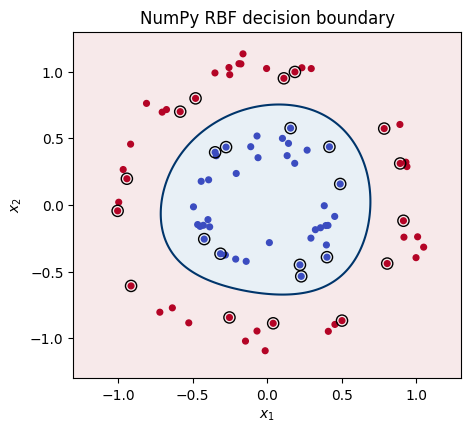

In [7]:
angles = rng.uniform(0, 2*np.pi, 120)
labels = np.r_[-np.ones(60), np.ones(60)]
radii = np.where(labels < 0, .45, 1.0) + rng.normal(0, .06, 120)
X_ring = np.column_stack([radii*np.cos(angles), radii*np.sin(angles)])
order = rng.permutation(120)
ring_train, ring_test = order[:84], order[84:]
gamma, C = 2.0, 1.0
rbf_model = fit_kernel_numpy(X_ring[ring_train], labels[ring_train],
                             C=C, kind='rbf', gamma=gamma)
train_score = kernel_score(rbf_model, X_ring[ring_train])
test_score = kernel_score(rbf_model, X_ring[ring_test])
train_accuracy = np.mean(np.where(train_score >= 0, 1, -1) == labels[ring_train])
test_accuracy = np.mean(np.where(test_score >= 0, 1, -1) == labels[ring_test])
print('NumPy RBF: epochs', rbf_model['epochs'],
      'support vectors', np.sum(rbf_model['alpha'] > 1e-7),
      'train accuracy', train_accuracy, 'test accuracy', test_accuracy)
print('RBF primal-dual gap:',
      kernel_primal_objective(rbf_model)-dual_objective(rbf_model))
print('largest KKT violation:', maximum_kkt_violation(rbf_model))
xx, yy = np.meshgrid(np.linspace(-1.3, 1.3, 180),
                     np.linspace(-1.3, 1.3, 180))
grid = np.column_stack([xx.ravel(), yy.ravel()])
score_grid = kernel_score(rbf_model, grid).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.contourf(xx, yy, score_grid, levels=[-100, 0, 100],
            colors=['#dce8f2', '#f4dee0'], alpha=.65)
ax.contour(xx, yy, score_grid, levels=[0], colors=['#00356b'])
ax.scatter(X_ring[ring_train, 0], X_ring[ring_train, 1],
           c=labels[ring_train], cmap='coolwarm', s=17)
support = rbf_model['alpha'] > 1e-7
ax.scatter(X_ring[ring_train][support, 0], X_ring[ring_train][support, 1],
           facecolors='none', edgecolors='black', s=65)
ax.set(xlabel='$x_1$', ylabel='$x_2$', title='NumPy RBF decision boundary')
plt.show()

## 6. Check against scikit-learn on identical data

Only now import `SVC`. We give it the same $C$, kernel, $\gamma$, training
rows, and labels. A solver can choose slightly different coefficients when
the optimum is numerically close; compare decision scores and predictions on
held-out rows rather than expecting bit-for-bit equal multipliers. For the
linear case, compare $w$, intercept, objective, and test scores. For the RBF
case, compare held-out scores and predictions. `support_` indexes the array
passed to `fit`, so its length can be compared with our count of nonzero
multipliers. `dual_coef_` stores $\alpha_i y_i$ for those support rows.
We require exact prediction agreement on this fixed example and a maximum
score difference below $10^{-3}$. These are checks of these data and solver
settings, not a guarantee for every dataset or parameter choice.

In [8]:
from sklearn.svm import SVC

reference_linear = SVC(kernel='linear', C=C_linear, tol=1e-6).fit(Xtr, ytr)
reference_rbf = SVC(kernel='rbf', C=C, gamma=gamma,
                    tol=1e-6).fit(X_ring[ring_train], labels[ring_train])
our_linear_score = kernel_score(linear_dual, Xte)
their_linear_score = reference_linear.decision_function(Xte)
our_rbf_score = kernel_score(rbf_model, X_ring[ring_test])
their_rbf_score = reference_rbf.decision_function(X_ring[ring_test])

def reference_dual_objective(reference, X, y, kind, gamma):
    alpha = np.zeros(len(y))
    alpha[reference.support_] = np.abs(reference.dual_coef_.ravel())
    weighted = alpha*y
    gram = kernel_matrix(X, X, kind=kind, gamma=gamma)
    return alpha.sum()-.5*weighted @ gram @ weighted

comparison = pd.DataFrame([
    {'fit': 'linear', 'our support vectors': np.sum(linear_dual['alpha'] > 1e-7),
     'SVC support vectors': len(reference_linear.support_),
     'maximum test-score difference': np.max(np.abs(our_linear_score-their_linear_score)),
     'test prediction agreement': np.mean((our_linear_score >= 0) ==
                                          (their_linear_score >= 0)),
     'dual objective difference': abs(dual_objective(linear_dual)-
         reference_dual_objective(reference_linear, Xtr, ytr, 'linear', gamma))},
    {'fit': 'RBF', 'our support vectors': np.sum(rbf_model['alpha'] > 1e-7),
     'SVC support vectors': len(reference_rbf.support_),
     'maximum test-score difference': np.max(np.abs(our_rbf_score-their_rbf_score)),
     'test prediction agreement': np.mean((our_rbf_score >= 0) ==
                                          (their_rbf_score >= 0)),
     'dual objective difference': abs(dual_objective(rbf_model)-
         reference_dual_objective(reference_rbf, X_ring[ring_train],
                                  labels[ring_train], 'rbf', gamma))},
])
display(comparison.round(5))
print('linear primal objective: NumPy subgradient',
      round(primal_objective(Xtr, ytr, w, b, C_linear), 5),
      'NumPy dual solution',
      round(primal_objective(Xtr, ytr, dual_w, linear_dual['b'], C_linear), 5),
      'SVC',
      round(primal_objective(Xtr, ytr, reference_linear.coef_[0],
                             reference_linear.intercept_[0], C_linear), 5))
assert np.all(comparison['test prediction agreement'] == 1.0)
assert np.all(comparison['maximum test-score difference'] < 1e-3)
assert np.all(comparison['our support vectors'] == comparison['SVC support vectors'])
assert np.all(comparison['dual objective difference'] < 1e-3)

,fit,our support vectors,SVC support vectors,maximum test-score difference,test prediction agreement,dual objective difference
0,linear,13,13,0.00006,1.0,0.0
1,RBF,24,24,0.00013,1.0,0.0


linear primal objective: NumPy subgradient 9.40476 NumPy dual solution 9.40474 SVC 9.40473


## Try it

1. Change $C$ to $0.1$ and $10$ for both NumPy and `SVC`. Report the support
   vector counts and held-out accuracies. What happens to margin violations?
2. Change the RBF $\gamma$ to $0.2$ and $20$ without changing the split.
   Plot the two boundaries and compare their test accuracies.
3. Replace the RBF kernel with `kind='linear'` on the rings. Predict the
   limitation before running the fit. Compare its boundary with the RBF fit.

For each experiment, use the **same data and parameter values** for both
implementations. Compare numerical outcomes, not only pictures.